# Priorización de vulnerabilidades explotadas: modelo para anticipar CISA KEV

**Autor:** Adrian Rodríguez Ortiz · **Curso:** Ciberseguridad y Data Intelligence, MSMK University · **Entrega:** capítulo 2 del Assignment Brief (notebook de modelado, lección 09)

## 0. Resumen ejecutivo

- **Pregunta.** ¿Anticipan los datos públicos de cada CVE si entrará en KEV en ≤ 90 días, para elegir parches semanales?
- **Modelo.** Gradient boosting en un pipeline único, entrenado con 2021-2024 y evaluado una sola vez con 2025-2026. Sin EPSS de hoy, que tendría fuga.
- **Mejora.** Con 30 CVEs por semana cubre el 29 % de los explotados frente al 20 % de CVSS (+10 puntos; IC 95 %: +3 a +16).
- **Límite.** El acierto llega tarde: el margen mediano antes de KEV es de 1 día (CVSS: 8). Sin EPSS histórico no hay anticipación útil para una ventana semanal.
- **Recomendación.** Usar el orden del modelo en lugar del de CVSS, fijar K con el responsable según el coste de omitir, y mantener la ventana de emergencia para todo CVE que entre en KEV.

In [1]:
# Paquetes extra (descomenta si faltan). kaleido 0.2.1 permite guardar los gráficos de plotly como imagen
# para que se vean en GitHub sin ejecutar el notebook.
# !pip install -q plotly scikit-learn pyarrow joblib scipy kaleido==0.2.1

import platform, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import joblib, sklearn
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from scipy.stats import chi2_contingency
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)

# Gráficos estáticos si hay kaleido (visibles en GitHub); si no, plotly interactivo.
try:
    import kaleido  # noqa: F401
    pio.renderers.default = "png"
except Exception:
    pass

def show(fig):
    try:
        fig.show()
    except Exception:
        fig.show(renderer="notebook")

RES = {}   # aquí se guardan los números que usa el resumen final

## 1. Del brief a una tarea de ML

El brief dejó abierta la pregunta: **¿pueden los datos anticipar qué CVEs entrarán en KEV, lo bastante bien para cambiar lo que parchea el responsable cada lunes?**

### 1.1 Qué cambia respecto al brief y por qué

1. **Objetivo con horizonte.** `y = 1` si entra en KEV en ≤ 90 días. Solo cuentan CVEs con 90 días de margen hasta la descarga.
2. **Métrica de decisión.** K = 30 CVEs por semana: la métrica principal es recall@K. Con un 0,3 % de positivos, accuracy y ROC-AUC engañan.
3. **Umbral por capacidad.** Con capacidad fija la lista es top-K. El volumen semanal sube de 435 CVEs (train) a 1.066 (test), así que K cubre cada vez menos.
4. **Objetivo medible.** Cobertura frente a ordenar por CVSS, con el mismo K, en el test temporal.

### 1.2 Tabla de la tarea

| Pregunta | Respuesta |
|---|---|
| Decisión | Qué CVEs entran cada lunes en la ventana de parcheo |
| Tipo de tarea | Clasificación binaria con probabilidad, para ordenar |
| Objetivo | `y`: entra en KEV en ≤ `HORIZON_DAYS` días |
| Grano | Un CVE, unos días tras su publicación |
| Variables | CVSS, vector, complejidad, autenticación, CWE, vendor (EPSS no, §4) |
| Línea base | CVSS ≥ 7, u ordenar por CVSS y coger K |
| Métrica | recall@K por semana; precision@K y PR-AUC |
| Negocio | % de explotados cubiertos con la misma carga |

> **Qué significa para el responsable.** Una lista de 30 CVEs por semana, ordenada por probabilidad de entrar en KEV, que se mide por cuántos explotados cubre frente a CVSS.

In [2]:
# ----- Parámetros del proyecto (todo lo que se puede discutir está aquí) -----
DATA_DIR        = Path("data")                 # ruta relativa al notebook
DOWNLOAD_DATE   = pd.Timestamp("2026-10-18")   # fecha de descarga de las tres fuentes
FIRST_DATE      = pd.Timestamp("2021-01-01")   # KEV empieza en nov-2021: solo CVEs de 2021 en adelante
HORIZON_DAYS    = 90                           # el CVE "entra a tiempo" si llega a KEV en <= 90 días
K               = 30                           # capacidad de la ventana semanal (supuesto del brief: pocas decenas)
TRAIN_END       = pd.Timestamp("2024-01-01")   # train: 2021-2023
VALID_END       = pd.Timestamp("2025-01-01")   # validación: 2024 · test: 2025 en adelante
COST_RATIO      = 20                           # SUPUESTO: un CVE explotado omitido cuesta 20 veces un parche de más

DATA_FILE       = DATA_DIR / "cves_kev_epss.parquet"   # salida de build_dataset.py
# Valores normalizados que cuentan como "red", "sin autenticación" y "complejidad baja"
NET, NOAUTH, LOWC = {"NETWORK"}, {"NONE"}, {"LOW"}

## 2. Datos y calidad

Tabla construida con `build_dataset.py` (CVE List, KEV y EPSS, descargados el 18/10/2026). Aquí se carga, se limpia y se cuenta cada paso.

In [3]:
assert DATA_FILE.exists(), f"No encuentro {DATA_FILE.resolve()}. Ejecuta build_dataset.py o copia el parquet a data/ (menos de 50 MB)."
raw = pd.read_parquet(DATA_FILE)
need = ["cveID", "published", "dateAdded", "en_KEV", "cvss", "cvss_vector", "cwe", "vendor", "product", "epss"]
missing_cols = [c for c in need if c not in raw.columns]
if missing_cols:
    raise KeyError(f"Faltan columnas {missing_cols}. Columnas disponibles: {list(raw.columns)}")
df = raw[need].rename(columns={"cveID": "id", "dateAdded": "date_added", "en_KEV": "kev"}).copy()
print(f"Fichero: {DATA_FILE.name} · {raw.shape[0]:,} filas × {raw.shape[1]} columnas")

# El vector de ataque, la complejidad y la autenticación están dentro de la cadena `cvss_vector`
# (v2: AV/AC/Au · v3.x: AV/AC/PR · v4.0: AV/AC/PR). Se extraen y se unifican los valores.
AV = {"N": "NETWORK", "A": "ADJACENT", "L": "LOCAL", "P": "PHYSICAL"}
AC = {"L": "LOW", "M": "MEDIUM", "H": "HIGH"}
PR = {"N": "NONE", "L": "LOW", "H": "HIGH"}
AU2 = {"N": "NONE", "S": "LOW", "M": "HIGH"}      # CVSS v2: sin autenticación / una / varias
def parse_vector(v):
    if not isinstance(v, str):
        return pd.Series([np.nan, np.nan, np.nan])
    p = dict(x.split(":", 1) for x in v.split("/") if ":" in x)
    auth = PR.get(p["PR"]) if "PR" in p else AU2.get(p.get("Au"))
    return pd.Series([AV.get(p.get("AV")), AC.get(p.get("AC")), auth])
parsed = df["cvss_vector"].drop_duplicates().to_frame()
parsed[["vector", "complexity", "auth"]] = parsed["cvss_vector"].apply(parse_vector)
df = df.merge(parsed, on="cvss_vector", how="left").drop(columns="cvss_vector")
print(df[["vector", "complexity", "auth"]].apply(lambda c: c.value_counts(dropna=False).to_dict()).to_string())

Fichero: cves_kev_epss.parquet · 236,253 filas × 14 columnas
vector        {'NETWORK': 152220, 'LOCAL': 41481, nan: 33641...
complexity    {'LOW': 178858, nan: 33641, 'HIGH': 23753, 'ME...
auth          {'NONE': 104873, 'LOW': 76436, nan: 33641, 'HI...


In [4]:
log = []
def step(nombre, n): log.append({"paso": nombre, "filas / casos": int(n)})

step("Filas iniciales", len(df))
for c in ["published", "date_added"]:
    df[c] = pd.to_datetime(df[c], errors="coerce", utc=True).dt.tz_localize(None)

n = df.duplicated("id").sum();                 step("Duplicados de cveID eliminados", n); df = df.drop_duplicates("id")
n = df["published"].isna().sum();              step("Sin fecha de publicación (eliminados)", n); df = df.dropna(subset=["published"])
n = (df["published"] < FIRST_DATE).sum();      step(f"Publicados antes de {FIRST_DATE.date()} (eliminados)", n); df = df[df["published"] >= FIRST_DATE]

df["cvss"] = pd.to_numeric(df["cvss"], errors="coerce")
bad = (df["cvss"] < 0) | (df["cvss"] > 10);    step("CVSS fuera de 0-10 (puesto a nulo)", bad.sum()); df.loc[bad, "cvss"] = np.nan
df["epss"] = pd.to_numeric(df["epss"], errors="coerce")

for c in ["vector", "complexity", "auth", "cwe"]:
    df[c] = df[c].astype("object").where(df[c].notna(), np.nan)
    df[c] = df[c].map(lambda v: v.strip().upper() if isinstance(v, str) else v)
v0 = df["vendor"].nunique()
df["vendor"] = df["vendor"].map(lambda v: v.strip().lower() if isinstance(v, str) else v)
df["vendor"] = df["vendor"].replace({"n/a": np.nan, "unknown": np.nan, "unspecified": np.nan, "": np.nan, "-": np.nan})
step(f"Vendors distintos antes → después de normalizar ({v0:,} → {df['vendor'].nunique():,})", v0 - df["vendor"].nunique())

step("CVSS ausente (se mantiene, es información)", df["cvss"].isna().sum())
step("CWE ausente (se mantiene)", df["cwe"].isna().sum())
step("Vector de ataque ausente (se mantiene)", df["vector"].isna().sum())
step("EPSS ausente (se mantiene)", df["epss"].isna().sum())

df["kev"] = pd.to_numeric(df["kev"], errors="coerce").fillna(0).astype(int)
step("Filas tras la limpieza", len(df))
display(pd.DataFrame(log))

,paso,filas / casos
0,Filas iniciales,236253
1,Duplicados de cveID eliminados,0
2,Sin fecha de publicación (eliminados),0
3,Publicados antes de 2021-01-01 (eliminados),0
4,CVSS fuera de 0-10 (puesto a nulo),0
5,Vendors distintos antes → después de normaliza...,1367
6,"CVSS ausente (se mantiene, es información)",33641
7,CWE ausente (se mantiene),83306
8,Vector de ataque ausente (se mantiene),33641
9,EPSS ausente (se mantiene),143


In [5]:
# ----- Objetivo con horizonte -----
df["days_to_kev"] = (df["date_added"] - df["published"]).dt.days
df["y"] = ((df["kev"] == 1) & (df["days_to_kev"] <= HORIZON_DAYS)).astype(int)
df["week"] = df["published"].dt.to_period("W").dt.start_time

cutoff = DOWNLOAD_DATE - pd.Timedelta(days=HORIZON_DAYS)
dfm = df[df["published"] <= cutoff].copy()          # CVEs a los que ya les ha dado tiempo de entrar en KEV
n_kev, n_in, n_late = int((df.kev == 1).sum()), int(df.y.sum()), int(((df.kev == 1) & (df.y == 0)).sum())

summary = pd.DataFrame({
    "concepto": ["CVEs en KEV (desde 2021)", f"…de ellos entran en ≤ {HORIZON_DAYS} días (y = 1)", f"…de ellos entran más tarde (y = 0 por definición)",
                 f"CVEs publicados después de {cutoff.date()} (excluidos: sin tiempo de entrar)", "Filas usadas para modelar", "Positivos en esas filas", "Tasa de positivos"],
    "valor": [n_kev, n_in, n_late, int((df.published > cutoff).sum()), len(dfm), int(dfm.y.sum()), f"{dfm.y.mean():.3%}"],
})
display(summary)
RES.update(n_rows=len(dfm), n_pos=int(dfm.y.sum()), prevalence=dfm.y.mean())

,concepto,valor
0,CVEs en KEV (desde 2021),1043
1,…de ellos entran en ≤ 90 días (y = 1),700
2,…de ellos entran más tarde (y = 0 por definición),343
3,CVEs publicados después de 2026-07-20 (excluid...,40941
4,Filas usadas para modelar,195312
5,Positivos en esas filas,637
6,Tasa de positivos,0.326%


> **Qué significa para el responsable.** Los datos son públicos y sin datos personales. Por cada 1.000 CVEs, solo unos 3 acaban en KEV en 90 días: cualquier lista semanal es una búsqueda de agujas, y KEV solo refleja lo que CISA ha visto explotado.

## 3. Qué mostró la exploración

Distribución del objetivo, tiempo hasta KEV (de ahí sale el horizonte) y las tres hipótesis del brief.

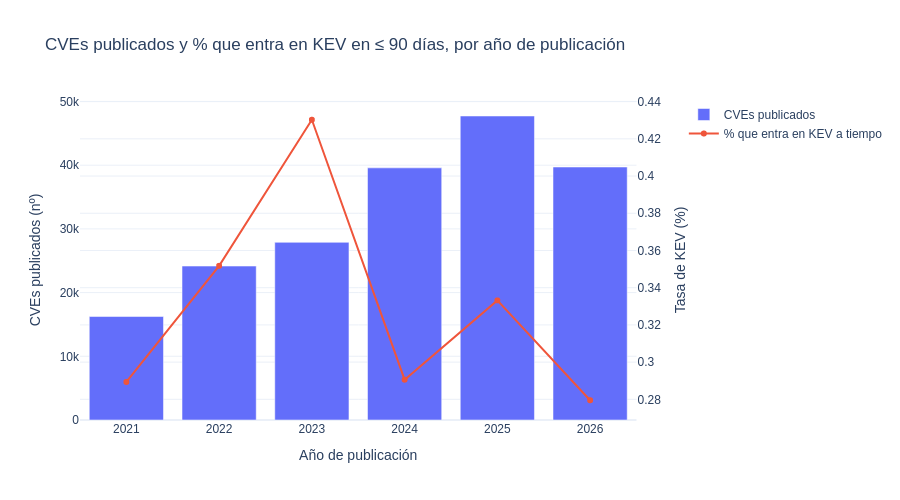

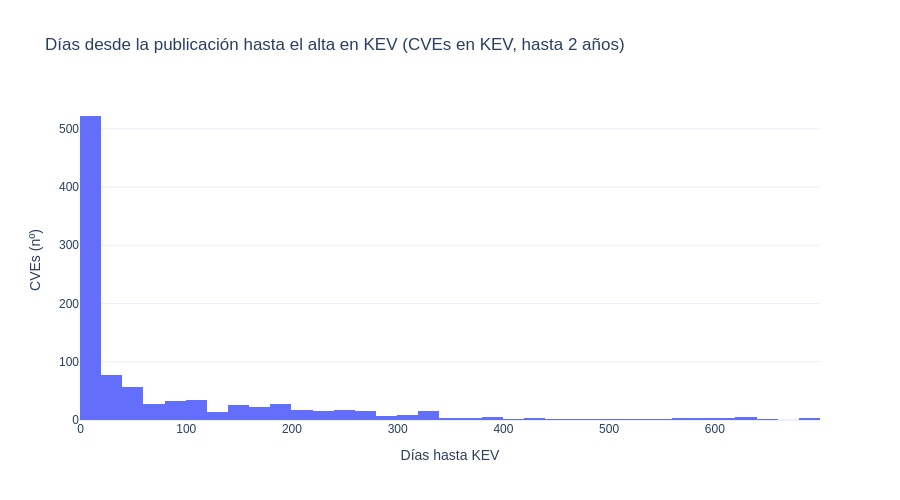

Fracción de los CVEs de KEV que entran dentro de N días: {30: '54%', 90: '67%', 180: '78%', 365: '90%'}


In [6]:
# Gráfico 1: tasa del objetivo por año de publicación (y número de CVEs)
g = dfm.groupby(dfm["published"].dt.year).agg(cves=("y", "size"), positivos=("y", "sum"))
g["tasa_pct"] = 100 * g["positivos"] / g["cves"]
fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_bar(x=g.index, y=g["cves"], name="CVEs publicados", secondary_y=False)
fig.add_scatter(x=g.index, y=g["tasa_pct"], name="% que entra en KEV a tiempo", mode="lines+markers", secondary_y=True)
fig.update_layout(title=f"CVEs publicados y % que entra en KEV en ≤ {HORIZON_DAYS} días, por año de publicación")
fig.update_xaxes(title_text="Año de publicación", dtick=1)
fig.update_yaxes(title_text="CVEs publicados (nº)", secondary_y=False)
fig.update_yaxes(title_text="Tasa de KEV (%)", secondary_y=True)
show(fig)

# Gráfico 2: días hasta KEV (justifica el horizonte)
d = df.loc[(df.kev == 1) & df.days_to_kev.notna(), "days_to_kev"].clip(lower=0)
share = {h: float((d <= h).mean()) for h in (30, 90, 180, 365)}
fig = px.histogram(d[d <= 730], nbins=60, title="Días desde la publicación hasta el alta en KEV (CVEs en KEV, hasta 2 años)",
                   labels={"value": "Días hasta KEV", "count": "CVEs"})
fig.update_layout(xaxis_title="Días hasta KEV", yaxis_title="CVEs (nº)", showlegend=False)
show(fig)
print("Fracción de los CVEs de KEV que entran dentro de N días:", {k: f"{v:.0%}" for k, v in share.items()})
RES["share_horizon"] = share[HORIZON_DAYS]

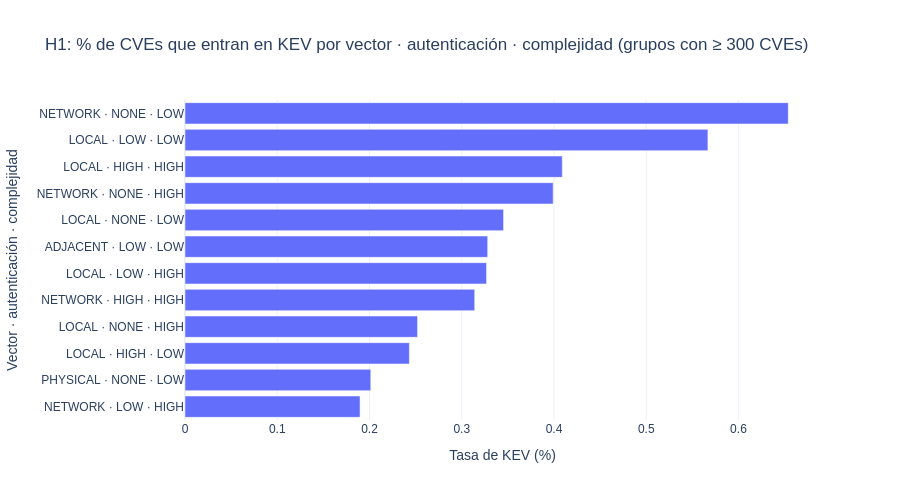

H1: tasa red+sin auth+baja = 0.65 % frente a 0.24 % (x2.7); chi² p = 6.22e-38; CVEs analizados: 164,233


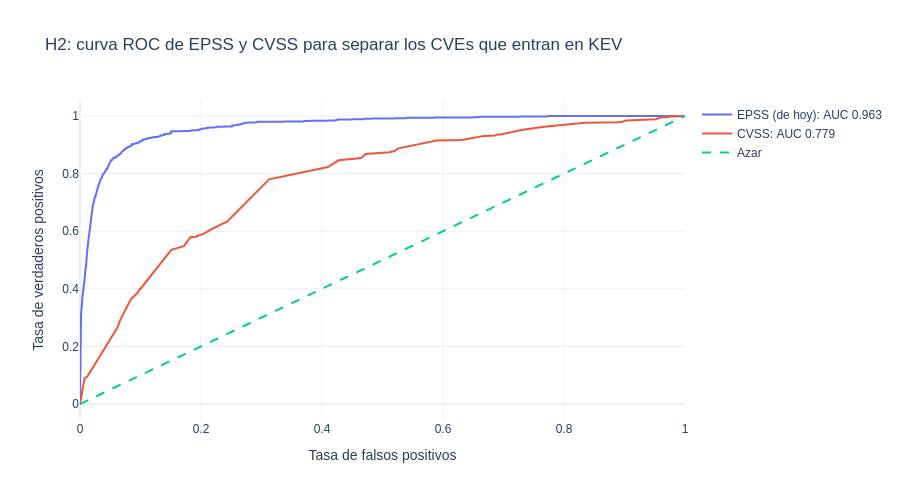

H2: AUC EPSS = 0.963 · AUC CVSS = 0.779  (ATENCIÓN: el EPSS descargado es el de hoy y ya puede incorporar la explotación)


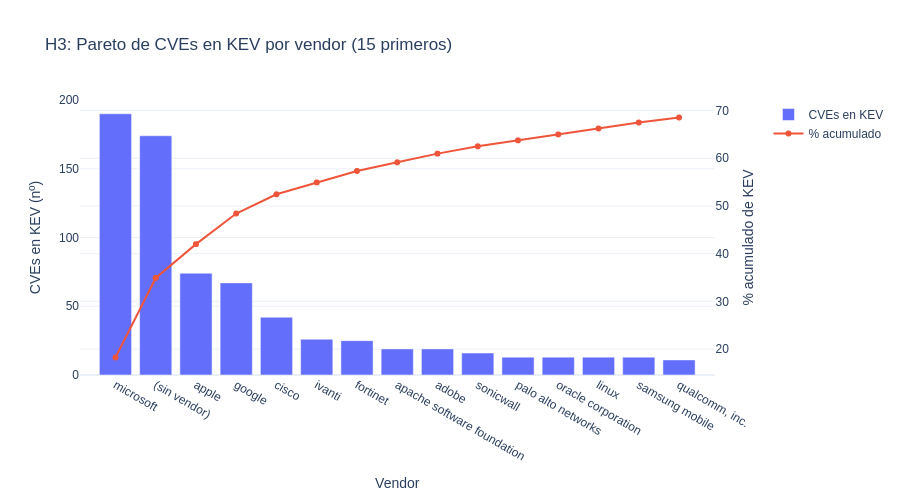

H3: los 10 primeros vendors acumulan el 63% de KEV


In [7]:
# ---- H1: red + sin autenticación + complejidad baja ----
h1 = dfm.dropna(subset=["vector"]).copy()
h1["combo"] = np.where(h1.vector.isin(NET) & h1.auth.isin(NOAUTH) & h1.complexity.isin(LOWC), "Red + sin auth + baja", "Resto")
tab = pd.crosstab(h1["combo"], h1["y"])
chi2, p_h1, _, _ = chi2_contingency(tab)
rate = h1.groupby("combo")["y"].mean() * 100
h1_ratio = rate.get("Red + sin auth + baja", np.nan) / rate.get("Resto", np.nan)

grp = (h1.assign(v=h1.vector.fillna("?"), a=h1.auth.fillna("?"), c=h1.complexity.fillna("?"))
         .groupby(["v", "a", "c"]).agg(n=("y", "size"), tasa=("y", "mean")).reset_index())
grp = grp[grp.n >= 300].sort_values("tasa", ascending=False).head(12)
grp["combinación"] = grp.v + " · " + grp.a + " · " + grp.c
fig = px.bar(grp.sort_values("tasa"), x=grp.sort_values("tasa")["tasa"] * 100, y="combinación", orientation="h",
             title="H1: % de CVEs que entran en KEV por vector · autenticación · complejidad (grupos con ≥ 300 CVEs)")
fig.update_layout(xaxis_title="Tasa de KEV (%)", yaxis_title="Vector · autenticación · complejidad")
show(fig)
print(f"H1: tasa red+sin auth+baja = {rate.get('Red + sin auth + baja'):.2f} % frente a {rate.get('Resto'):.2f} % (x{h1_ratio:.1f}); chi² p = {p_h1:.2e}; CVEs analizados: {len(h1):,}")

# ---- H2: EPSS vs CVSS ----
h2 = dfm.dropna(subset=["epss", "cvss"])
auc_epss, auc_cvss = roc_auc_score(h2.y, h2.epss), roc_auc_score(h2.y, h2.cvss)
fig = go.Figure()
for nombre, col, auc in [("EPSS (de hoy)", "epss", auc_epss), ("CVSS", "cvss", auc_cvss)]:
    fpr, tpr, _ = roc_curve(h2.y, h2[col]); fig.add_scatter(x=fpr, y=tpr, name=f"{nombre}: AUC {auc:.3f}", mode="lines")
fig.add_scatter(x=[0, 1], y=[0, 1], name="Azar", mode="lines", line=dict(dash="dash"))
fig.update_layout(title="H2: curva ROC de EPSS y CVSS para separar los CVEs que entran en KEV", xaxis_title="Tasa de falsos positivos", yaxis_title="Tasa de verdaderos positivos")
show(fig)
print(f"H2: AUC EPSS = {auc_epss:.3f} · AUC CVSS = {auc_cvss:.3f}  (ATENCIÓN: el EPSS descargado es el de hoy y ya puede incorporar la explotación)")

# ---- H3: concentración por vendor (sobre todos los CVEs de KEV desde 2021) ----
kv = df[df.kev == 1].vendor.fillna("(sin vendor)").value_counts()
top10_share = kv.head(10).sum() / kv.sum()
pareto = kv.head(15).to_frame("n"); pareto["acum_pct"] = 100 * kv.head(15).cumsum() / kv.sum()
fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_bar(x=pareto.index, y=pareto["n"], name="CVEs en KEV", secondary_y=False)
fig.add_scatter(x=pareto.index, y=pareto["acum_pct"], name="% acumulado", mode="lines+markers", secondary_y=True)
fig.update_layout(title="H3: Pareto de CVEs en KEV por vendor (15 primeros)")
fig.update_xaxes(title_text="Vendor"); fig.update_yaxes(title_text="CVEs en KEV (nº)", secondary_y=False); fig.update_yaxes(title_text="% acumulado de KEV", secondary_y=True)
show(fig)
print(f"H3: los 10 primeros vendors acumulan el {top10_share:.0%} de KEV")

RES.update(h1_ratio=h1_ratio, h1_p=p_h1, auc_epss_today=auc_epss, auc_cvss=auc_cvss, top10_share=top10_share)

In [8]:
hyp = pd.DataFrame([
    {"hipótesis": "H1 red + sin auth + complejidad baja llega más a KEV",
     "veredicto": "apoyada" if (p_h1 < 0.01 and h1_ratio > 1) else "refutada",
     "evidencia": f"tasa x{h1_ratio:.1f} frente al resto, chi² p = {p_h1:.1e}, sobre {len(h1):,} CVEs con vector"},
    {"hipótesis": "H2 EPSS separa mejor que CVSS",
     "veredicto": "no testable aún (EPSS de hoy)",
     "evidencia": f"AUC EPSS {auc_epss:.3f} vs CVSS {auc_cvss:.3f}, pero el EPSS descargado ya conoce la explotación; falta el EPSS de los días tras la publicación"},
    {"hipótesis": "H3 pocos vendors concentran KEV",
     "veredicto": "apoyada" if top10_share > 0.5 else "refutada",
     "evidencia": f"los 10 primeros vendors suman el {top10_share:.0%} de KEV"},
])
display(hyp)

,hipótesis,veredicto,evidencia
0,H1 red + sin auth + complejidad baja llega más...,apoyada,"tasa x2.7 frente al resto, chi² p = 6.2e-38, s..."
1,H2 EPSS separa mejor que CVSS,no testable aún (EPSS de hoy),"AUC EPSS 0.963 vs CVSS 0.779, pero el EPSS des..."
2,H3 pocos vendors concentran KEV,apoyada,los 10 primeros vendors suman el 63% de KEV


> **Qué significa para el responsable.** Los CVEs de red, sin credenciales y de complejidad baja acaban en KEV casi tres veces más que el resto (0,65 % frente a 0,24 %). Diez fabricantes concentran el 63 % de KEV. EPSS no se puede evaluar todavía: el de hoy ya sabe qué se explotó. Para priorizar, el vector pesa más que el CVSS solo, y conviene vigilar primero los productos de esos diez fabricantes.

## 4. Variables y control de fugas

Por cada columna, la pregunta es: *¿tendría este valor unos días después de publicarse el CVE?*

| Variable | Cómo se construye | Por qué ayuda | ¿Disponible? |
|---|---|---|---|
| `cvss`, `cvss_missing` | Puntuación 0-10 y marca de ausencia (14 % sin CVSS) | Es la regla actual; la ausencia también informa | Sí |
| `vector`, `complexity`, `auth`, `vcombo` | Categorías del vector CVSS y su combinación | H1: red, sin credenciales, baja complejidad | Sí |
| `cwe` | Tipo de fallo; raros agrupados | Algunos tipos se explotan mucho más | Sí |
| `vendor` | Normalizado; raros agrupados | H3: explotación concentrada en pocos fabricantes | Sí |
| `epss` | Probabilidad de explotación a 30 días | H2 | **Solo el de días tras la publicación** (el de hoy tiene fuga) |
| `kev`, `date_added`, `days_to_kev` | Definen el objetivo | — | **No**: son el resultado |

**EPSS.** El de la tabla es de 17/10/2026 y ya sabe qué se explotó: usarlo para predecir sería fuga. El modelo principal no lo usa; la variante con él es solo cota optimista. Imputación, escalado y codificación se ajustan solo con train.

In [9]:
%%writefile features.py
"""Ingeniería de variables del modelo. Se importa desde el notebook y desde el despliegue."""
import pandas as pd

RAW_COLUMNS = ["cvss", "vector", "complexity", "auth", "cwe", "vendor"]   # columnas crudas que recibe el pipeline
NUM_FEATURES = ["cvss", "cvss_missing"]
CAT_FEATURES = ["vector", "complexity", "auth", "cwe", "vendor", "vcombo"]


def add_features(X, use_epss=False):
    X = X.copy()
    for c in ["vector", "complexity", "auth", "cwe", "vendor"]:
        X[c] = X[c].astype("object").where(X[c].notna(), "missing").astype(str).str.strip().str.upper()
    X["cvss"] = pd.to_numeric(X["cvss"], errors="coerce")
    X["cvss_missing"] = X["cvss"].isna().astype(int)
    X["vcombo"] = X["vector"] + "|" + X["auth"] + "|" + X["complexity"]
    cols = NUM_FEATURES + CAT_FEATURES
    if use_epss:
        X["epss"] = pd.to_numeric(X["epss"], errors="coerce")
        cols = ["epss"] + cols
    return X[cols]

Overwriting features.py


In [10]:
import importlib, features
importlib.reload(features)
from features import add_features, RAW_COLUMNS, NUM_FEATURES, CAT_FEATURES

# Control de fugas: ninguna columna que defina el objetivo puede entrar como entrada del modelo
FORBIDDEN = {"kev", "date_added", "days_to_kev", "y", "week", "id"}
assert not FORBIDDEN & set(RAW_COLUMNS), "¡Fuga! Una columna del objetivo está entre las entradas"
print("Entradas crudas del modelo:", RAW_COLUMNS, "· (variante optimista añade: epss)")

def build_pipeline(kind, use_epss=False):
    num = (["epss"] if use_epss else []) + NUM_FEATURES
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, max_categories=40, sparse_output=False), CAT_FEATURES),
    ])
    if kind == "logreg":
        clf = LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000)
    else:
        clf = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.1, max_iter=150, min_samples_leaf=50,
                                             class_weight="balanced", early_stopping=False, random_state=SEED)
    return Pipeline([("feat", FunctionTransformer(add_features, kw_args={"use_epss": use_epss})), ("pre", pre), ("clf", clf)])

Entradas crudas del modelo: ['cvss', 'vector', 'complexity', 'auth', 'cwe', 'vendor'] · (variante optimista añade: epss)


> **Qué significa para el responsable.** El modelo solo mira datos que existen al publicarse el CVE: puntuación, tipo de ataque, tipo de fallo y fabricante. No ve nada del futuro. La señal de EPSS no se usa hasta tener su valor histórico, para no hacer trampas.

## 5. Partición temporal y líneas base

Train 2021-2023, validación 2024 y test desde 2025: se entrena con el pasado y se prueba con el futuro. El test no se toca hasta la sección 8. La lista se elige por semana de publicación.

Líneas base: (a) al azar; (b) ordenar por CVSS y coger K; (c) regla CVSS ≥ 7, sin límite de carga, reportada aparte.

In [11]:
dfm = dfm.sort_values("published").reset_index(drop=True)
train = dfm[dfm.published < TRAIN_END]
valid = dfm[(dfm.published >= TRAIN_END) & (dfm.published < VALID_END)]
test  = dfm[dfm.published >= VALID_END]
dev   = dfm[dfm.published < VALID_END]          # train + validación (para CV y búsqueda)
display(pd.DataFrame({
    "partición": ["train", "validación", "test"],
    "periodo": [f"{p.published.min().date()} → {p.published.max().date()}" for p in (train, valid, test)],
    "CVEs": [len(p) for p in (train, valid, test)],
    "positivos": [int(p.y.sum()) for p in (train, valid, test)],
    "CVEs por semana (media)": [round(p.groupby("week").size().mean()) for p in (train, valid, test)],
}))

def topk_mask(frame, score, k=K, seed=SEED):
    """True en los k CVEs de mayor puntuación de cada semana de publicación (empates al azar, con semilla)."""
    rng = np.random.default_rng(seed)
    s = np.nan_to_num(np.asarray(score, dtype=float), nan=-1.0)
    wk = frame["week"].values.astype("datetime64[ns]")
    order = np.lexsort((rng.random(len(s)), -s, wk))
    w = wk[order]
    new = np.r_[True, w[1:] != w[:-1]]
    start = np.maximum.accumulate(np.where(new, np.arange(len(w)), 0))
    rank = np.arange(len(w)) - start
    mask = np.zeros(len(s), dtype=bool); mask[order[rank < k]] = True
    return mask

def eval_scores(name, frame, score, k=K):
    y = frame["y"].values
    s = np.nan_to_num(np.asarray(score, dtype=float), nan=-1.0)
    m = topk_mask(frame, s, k)
    return {"modelo": name, "PR-AUC": average_precision_score(y, s), "ROC-AUC": roc_auc_score(y, s),
            f"recall@{k}/sem": y[m].sum() / y.sum(), f"precision@{k}/sem": y[m].sum() / m.sum()}

def eval_rule_cvss7(frame):
    y = frame["y"].values; m = (frame["cvss"] >= 7).values
    load = pd.Series(m).groupby(frame["week"].values).sum()
    return {"recall": y[m].sum() / y.sum(), "precision": y[m].sum() / m.sum(), "carga semanal media": load.mean(), "carga semanal máx": load.max()}

base_valid = pd.DataFrame([
    eval_scores("Al azar", valid, np.zeros(len(valid))),
    eval_scores("Ordenar por CVSS (top-K)", valid, valid["cvss"].values),
]).round(4)
display(base_valid)
r7 = eval_rule_cvss7(valid)
print(f"Regla CVSS ≥ 7 en validación: recall {r7['recall']:.1%}, precision {r7['precision']:.2%}, carga {r7['carga semanal media']:.0f} CVEs/semana de media (máx {r7['carga semanal máx']:.0f}) frente a K = {K}")

,partición,periodo,CVEs,positivos,CVEs por semana (media)
0,train,2021-01-01 → 2023-12-31,68298,252,435
1,validación,2024-01-01 → 2024-12-31,39579,115,747
2,test,2025-01-01 → 2026-07-20,87435,270,1066


,modelo,PR-AUC,ROC-AUC,recall@30/sem,precision@30/sem
0,Al azar,0.0029,0.5000,0.0348,0.0025
1,Ordenar por CVSS (top-K),0.0092,0.7807,0.1913,0.0138


Regla CVSS ≥ 7 en validación: recall 85.2%, precision 0.56%, carga 330 CVEs/semana de media (máx 895) frente a K = 30


> **Qué significa para el responsable.** La regla de hoy manda unas 330 a 475 tareas por semana y cubre la mayoría de lo que acaba explotado. Con solo K tareas, el modelo tiene que cubrir más con las mismas.

## 6. Modelos candidatos

Dos pipelines completos de columnas crudas a probabilidad: una **regresión logística** (simple, con `class_weight="balanced"`) y un **gradient boosting** (captura interacciones sin diseñarlas a mano). La fila con EPSS de hoy es solo cota optimista.

In [12]:
Xtr, ytr, Xva, yva = train[RAW_COLUMNS + ["epss"]], train["y"], valid[RAW_COLUMNS + ["epss"]], valid["y"]

rows, scores_valid = [], {}
for kind, label in [("logreg", "Regresión logística"), ("hgb", "Gradient boosting")]:
    pipe = build_pipeline(kind, use_epss=False).fit(Xtr, ytr)
    scores_valid[label] = pipe.predict_proba(Xva)[:, 1]
    rows.append(eval_scores(label, valid, scores_valid[label]))
pipe_e = build_pipeline("hgb", use_epss=True).fit(Xtr, ytr)
rows.append(eval_scores("Gradient boosting + EPSS de hoy (cota optimista, con fuga)", valid, pipe_e.predict_proba(Xva)[:, 1]))
rows.append(eval_scores("Solo EPSS de hoy (con fuga)", valid, valid["epss"].values))

comp = pd.concat([base_valid, pd.DataFrame(rows).round(4)], ignore_index=True)
display(comp)
RES["valid_table"] = comp

,modelo,PR-AUC,ROC-AUC,recall@30/sem,precision@30/sem
0,Al azar,0.0029,0.5000,0.0348,0.0025
1,Ordenar por CVSS (top-K),0.0092,0.7807,0.1913,0.0138
2,Regresión logística,0.0169,0.8315,0.2609,0.0189
3,Gradient boosting,0.0210,0.8528,0.2870,0.0208
4,Gradient boosting + EPSS de hoy (cota optimist...,0.3699,0.9809,0.8696,0.0629
5,Solo EPSS de hoy (con fuga),0.3123,0.9715,0.8174,0.0591


> **Qué significa para el responsable.** Con las mismas 30 CVEs por semana, el modelo cubre el 29 % de los explotados en validación frente al 19 % de ordenar por CVSS. Las dos filas con EPSS de hoy (cubren cerca del 87 %) son un techo teórico que usa información posterior a la publicación: no se pueden usar todavía.

## 7. Métrica y coste de los errores

La lista es un top-K, no un umbral. Su matriz de confusión, en términos de negocio:

- **Verdadero positivo:** parche útil, se adelantó a una explotación real.
- **Falso positivo:** parche de más, horas del equipo y una ventana de mantenimiento.
- **Falso negativo:** explotado que no estaba en la lista. Es el error caro.

La métrica principal es **recall@K**, con precision@K para vigilar el ruido. PR-AUC compara modelos sin fijar K. El coste relativo (`COST_RATIO`, 20 a 1) es un supuesto que se prueba en §7.1.

### 7.0 Objetivos y métricas frente a los datos

| Objetivo | Métrica | Columna que la sostiene |
|---|---|---|
| Cubrir lo que acaba en KEV | recall@K por semana | `y`, `week` |
| No llenar la lista de ruido | precision@K | `y` |
| Ordenar bien en todo el rango | PR-AUC | `y` |
| Equilibrar omisiones y parches de más | coste semanal = ratio × omitidos + parches de más | `COST_RATIO` (supuesto) |
| Avisar con antelación | margen mediano antes de KEV | `days_to_kev` |
| Lista fiable semana a semana | % de semanas con al menos un cubierto | `week` |
| Que la probabilidad signifique algo | calibración y Brier | `y`, probabilidad |

La carga es K por construcción. Lo que cambia es cuánto cubre K del total: el volumen semanal pasa de 435 CVEs en train a 1.066 en test.

,Acaba en KEV (y=1),No acaba en KEV (y=0)
En la lista (parchear),33,1557
Fuera de la lista,82,37907


Validación, gradient boosting, K=30/semana: 33 explotados cubiertos, 82 omitidos, 1557 parches sin explotación.


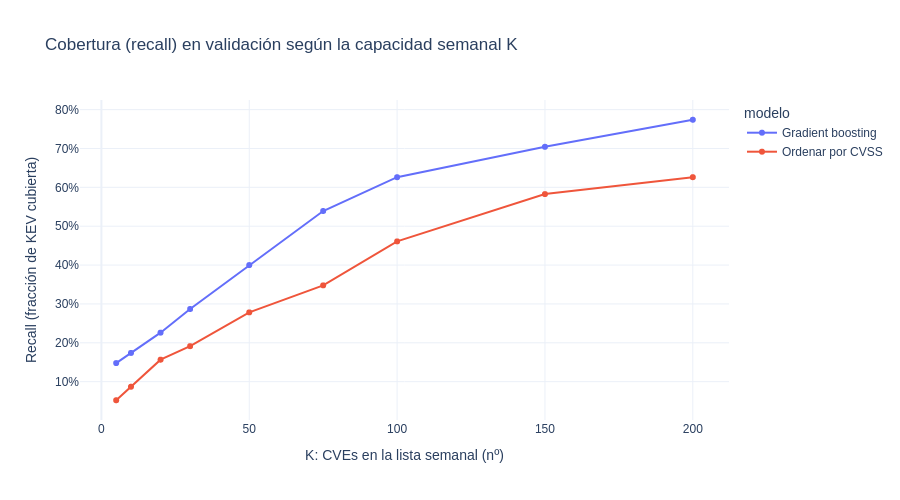

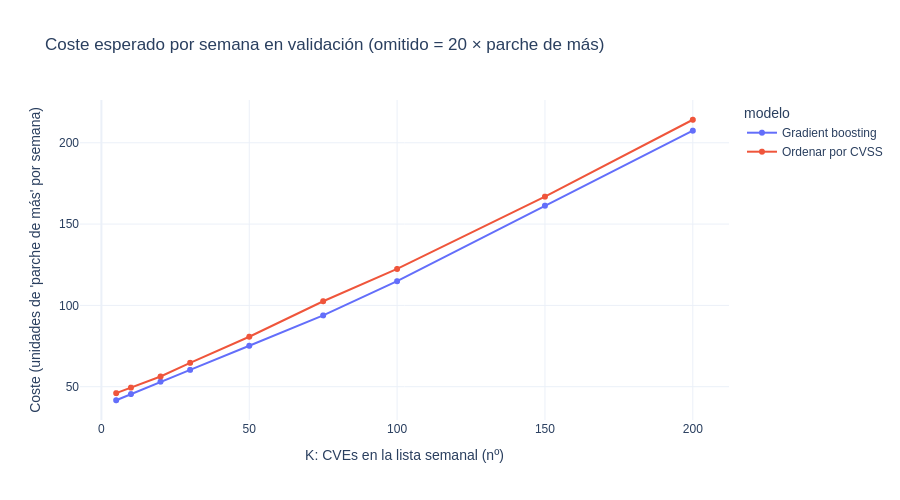

In [13]:
s_hgb = scores_valid["Gradient boosting"]
m = topk_mask(valid, s_hgb, K); y = valid["y"].values
tp, fp = int((m & (y == 1)).sum()), int((m & (y == 0)).sum())
fn, tn = int(((~m) & (y == 1)).sum()), int(((~m) & (y == 0)).sum())
display(pd.DataFrame([[tp, fn], [fp, tn]], index=["Acaba en KEV (y=1)", "No acaba en KEV (y=0)"],
                     columns=["En la lista (parchear)", "Fuera de la lista"]).T)
print(f"Validación, gradient boosting, K={K}/semana: {tp} explotados cubiertos, {fn} omitidos, {fp} parches sin explotación.")

ks = [5, 10, 20, 30, 50, 75, 100, 150, 200]
curve = []
for k in ks:
    for nombre, s in [("Gradient boosting", s_hgb), ("Ordenar por CVSS", valid["cvss"].values)]:
        mk = topk_mask(valid, s, k); curve.append({"K": k, "modelo": nombre, "recall": y[mk].sum() / y.sum(),
                                                    "coste": (COST_RATIO * ((~mk) & (y == 1)).sum() + (mk & (y == 0)).sum()) / valid.week.nunique()})
curve = pd.DataFrame(curve)
fig = px.line(curve, x="K", y="recall", color="modelo", markers=True, title="Cobertura (recall) en validación según la capacidad semanal K")
fig.update_layout(xaxis_title="K: CVEs en la lista semanal (nº)", yaxis_title="Recall (fracción de KEV cubierta)", yaxis_tickformat=".0%"); show(fig)
fig = px.line(curve, x="K", y="coste", color="modelo", markers=True, title=f"Coste esperado por semana en validación (omitido = {COST_RATIO} × parche de más)")
fig.update_layout(xaxis_title="K: CVEs en la lista semanal (nº)", yaxis_title="Coste (unidades de 'parche de más' por semana)"); show(fig)

> **Qué significa para el responsable.** Con K = 30, la validación cubre 33 de los 115 explotados y omite 82. Ampliar K cubre más, pero añade muchos parches de más: el coste mínimo está en el K más bajo probado (sección 7.1). La elección de K es, por tanto, de capacidad y de tolerancia al riesgo.

### 7.1 Sensibilidad al coste y calibración (solo validación)

El ratio de coste es un supuesto: se prueban varios valores y se busca el K que minimiza el coste. Todo en validación; el test no interviene.

In [14]:
# Sensibilidad: ¿cambia la conclusión si el ratio de coste no es 20:1? (solo validación)
RATIOS = [5, 10, 20, 50]
KS = [5, 10, 20, 30, 50, 75, 100, 150, 200, 300]
n_weeks = valid["week"].nunique()
rows = []
for ratio in RATIOS:
    for k in KS:
        for nombre, s in [("Gradient boosting", s_hgb), ("Ordenar por CVSS", valid["cvss"].values)]:
            mk = topk_mask(valid, s, k)
            coste = (ratio * ((~mk) & (y == 1)).sum() + (mk & (y == 0)).sum()) / n_weeks
            rows.append({"ratio": ratio, "K": k, "modelo": nombre, "coste por semana": coste})
sens = pd.DataFrame(rows)

mejor = sens.loc[sens.groupby(["ratio", "modelo"])["coste por semana"].idxmin()]
print("K que minimiza el coste semanal, por ratio y modelo:")
display(mejor.sort_values(["ratio", "modelo"]).reset_index(drop=True).round(2))

a_k = sens[sens["K"] == K].pivot(index="ratio", columns="modelo", values="coste por semana").round(2)
print(f"Coste semanal con K = {K}, por ratio:")
display(a_k.rename_axis(f"ratio de coste (K = {K})"))

K que minimiza el coste semanal, por ratio y modelo:


,ratio,K,modelo,coste por semana
0,5,5,Gradient boosting,13.92
1,5,5,Ordenar por CVSS,15.17
2,10,5,Gradient boosting,23.17
3,10,5,Ordenar por CVSS,25.45
4,20,5,Gradient boosting,41.66
5,20,5,Ordenar por CVSS,46.02
6,50,5,Gradient boosting,97.13
7,50,5,Ordenar por CVSS,107.72


Coste semanal con K = 30, por ratio:


modelo,Gradient boosting,Ordenar por CVSS
ratio de coste (K = 30),,
5,37.11,38.36
10,44.85,47.13
20,60.32,64.68
50,106.74,117.32


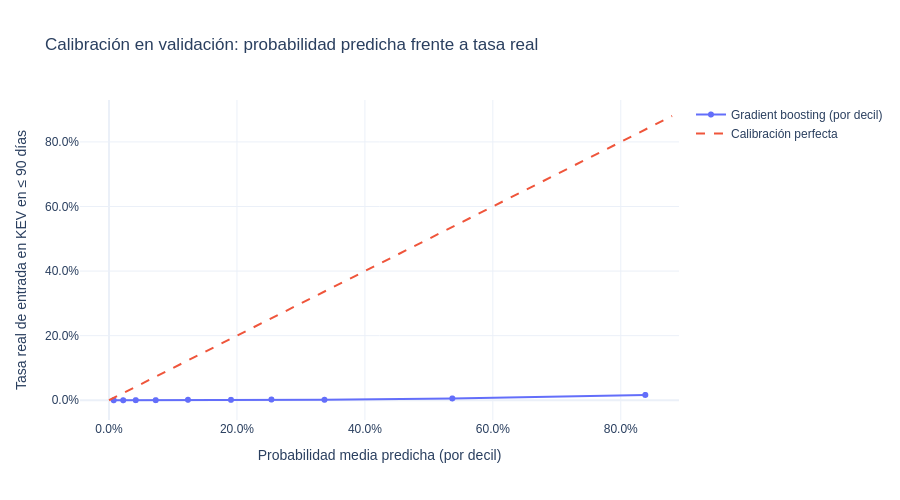

,decil,prob_predicha,tasa_real,CVEs
0,1,0.0073,0.0000,3958
1,2,0.0222,0.0000,3958
2,3,0.0418,0.0003,3958
3,4,0.0730,0.0003,3958
4,5,0.1234,0.0015,3958
5,6,0.1906,0.0013,3957
6,7,0.2539,0.0023,3958
7,8,0.3368,0.0015,3958
8,9,0.5366,0.0056,3958
9,10,0.8383,0.0164,3958


Brier del gradient boosting: 0.12325 · Brier de predecir siempre la tasa media: 0.00290 (menor es mejor)


In [15]:
# Calibración en validación: ¿la probabilidad del modelo coincide con la tasa real?
from sklearn.metrics import brier_score_loss

cal = pd.DataFrame({"p": s_hgb, "y": y})
cal["decil"] = pd.qcut(cal["p"].rank(method="first"), 10, labels=False) + 1
tab_cal = (cal.groupby("decil")
              .agg(prob_predicha=("p", "mean"), tasa_real=("y", "mean"), CVEs=("y", "size"))
              .reset_index())
fin = float(max(tab_cal["prob_predicha"].max(), tab_cal["tasa_real"].max()) * 1.05)

fig = go.Figure()
fig.add_scatter(x=tab_cal["prob_predicha"], y=tab_cal["tasa_real"], mode="lines+markers",
                name="Gradient boosting (por decil)")
fig.add_scatter(x=[0, fin], y=[0, fin], mode="lines", name="Calibración perfecta",
                line=dict(dash="dash"))
fig.update_layout(title="Calibración en validación: probabilidad predicha frente a tasa real")
fig.update_xaxes(title_text="Probabilidad media predicha (por decil)", tickformat=".1%")
fig.update_yaxes(title_text="Tasa real de entrada en KEV en ≤ 90 días", tickformat=".1%")
show(fig)
display(tab_cal.round(4))
print(f"Brier del gradient boosting: {brier_score_loss(y, s_hgb):.5f} · "
      f"Brier de predecir siempre la tasa media: {brier_score_loss(y, np.full(len(y), y.mean())):.5f} "
      "(menor es mejor)")

> **Qué significa para el responsable.** El modelo cuesta menos que CVSS en todos los ratios, tanto con K = 5 como con K = 30, así que esa conclusión no depende del supuesto. Pero el coste mínimo está en K = 5, el mínimo de la rejilla: con los datos de validación, K = 30 solo compensa si omitir un explotado cuesta más de unas 82 veces un parche de más. Con 20 a 1, la lista de 5 cuesta menos (41,7 frente a 60,3 por semana) pero cubre el 15 % frente al 29 %. Es una decisión de capacidad y de riesgo, no de modelo.
>
> La calibración dice que el número de cada CVE no es un porcentaje: el decil más alto tiene una tasa real del 1,6 % frente a una predicción media del 84 %. Sirve para ordenar, no para decir "hay un 30 % de probabilidad".

## 8. Validación y ajuste

Tres pasos, sin mirar el test: (1) validación cruzada temporal de 4 cortes, para medir la estabilidad; (2) búsqueda aleatoria de hiperparámetros, optimizando PR-AUC; (3) **una sola evaluación en el test**, con el mejor modelo reentrenado con train + validación.

In [16]:
dev = dev.sort_values("published").reset_index(drop=True)
Xdev, ydev = dev[RAW_COLUMNS + ["epss"]], dev["y"]
tscv = TimeSeriesSplit(n_splits=4)

def cv_table(builders):
    out = []
    for i, (a, b) in enumerate(tscv.split(Xdev), 1):
        fold = dev.iloc[b]
        for name, build in builders.items():
            if build is None:      # línea base CVSS, sin ajuste
                s = fold["cvss"].values
            else:
                s = build().fit(Xdev.iloc[a], ydev.iloc[a]).predict_proba(Xdev.iloc[b])[:, 1]
            r = eval_scores(name, fold, s); r["corte"] = i; r["periodo"] = f"{fold.published.min().date()} → {fold.published.max().date()}"; out.append(r)
    return pd.DataFrame(out)

cv = cv_table({"CVSS": None, "Regresión logística": lambda: build_pipeline("logreg"), "Gradient boosting": lambda: build_pipeline("hgb")})
display(cv.pivot(index="corte", columns="modelo", values=f"recall@{K}/sem").round(3).assign(periodo=cv.drop_duplicates("corte").set_index("corte")["periodo"]))
resumen_cv = cv.groupby("modelo")[["PR-AUC", f"recall@{K}/sem", f"precision@{K}/sem"]].agg(["mean", "std"]).round(4)
display(resumen_cv)
RES["cv"] = resumen_cv

modelo,CVSS,Gradient boosting,Regresión logística,periodo
corte,,,,
1,0.448,0.507,0.552,2022-03-23 → 2023-02-09
2,0.220,0.470,0.500,2023-02-09 → 2023-11-16
3,0.151,0.358,0.396,2023-11-16 → 2024-06-09
4,0.176,0.257,0.230,2024-06-09 → 2024-12-31


PR-AUC         recall@30/sem         precision@30/sem  \
                       mean     std          mean     std             mean   
modelo                                                                       
CVSS                 0.0126  0.0032        0.2486  0.1358           0.0156   
Gradient boosting    0.0335  0.0099        0.3982  0.1135           0.0261   
Regresión logística  0.0370  0.0229        0.4195  0.1422           0.0272   

                             
                        std  
modelo                       
CVSS                 0.0053  
Gradient boosting    0.0082  
Regresión logística  0.0095

In [17]:
search = RandomizedSearchCV(
    build_pipeline("hgb"),
    param_distributions={"clf__max_depth": [2, 3, 4, 6], "clf__learning_rate": [0.03, 0.05, 0.1],
                         "clf__max_iter": [100, 150, 250], "clf__min_samples_leaf": [20, 50, 100, 200],
                         "clf__l2_regularization": [0.0, 0.1, 1.0, 10.0]},
    n_iter=8, cv=TimeSeriesSplit(n_splits=3), scoring="average_precision", random_state=SEED, n_jobs=-1, refit=True)
search.fit(dev[RAW_COLUMNS + ["epss"]], dev["y"])
print("Mejores hiperparámetros:", search.best_params_)
print(f"PR-AUC medio en CV temporal: {search.best_score_:.4f}")
final = search.best_estimator_      # ya reentrenado con train + validación

Mejores hiperparámetros: {'clf__min_samples_leaf': 100, 'clf__max_iter': 150, 'clf__max_depth': 6, 'clf__learning_rate': 0.05, 'clf__l2_regularization': 0.1}
PR-AUC medio en CV temporal: 0.0370


,modelo,PR-AUC,ROC-AUC,recall@30/sem,precision@30/sem
0,Al azar,0.0031,0.5000,0.0444,0.0049
1,Ordenar por CVSS (top-K),0.0163,0.8052,0.1963,0.0217
2,Regresión logística,0.0364,0.8387,0.3000,0.0331
3,Gradient boosting ajustado (MODELO FINAL),0.0350,0.8403,0.2926,0.0323
4,Gradient boosting + EPSS de hoy (cota optimist...,0.3763,0.9747,0.7926,0.0875


Regla CVSS ≥ 7 en test: recall 88.5%, precision 0.61%, carga media 475 CVEs/semana
recall@30: modelo 29.3% · CVSS 19.6% · diferencia +9.6% (IC 95 % bootstrap por semanas: +3.4% a +15.5%)


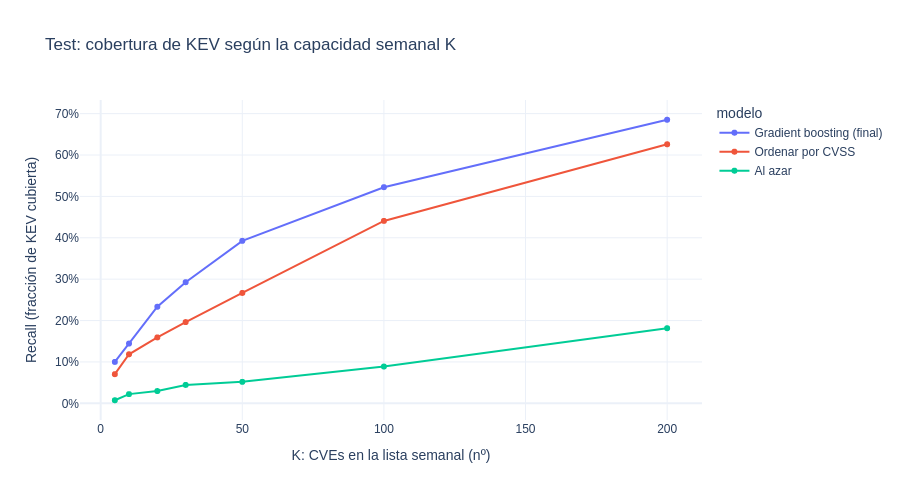

In [18]:
# ===== ÚNICA evaluación en test =====
Xte, yte = test[RAW_COLUMNS + ["epss"]], test["y"].values
s_final = final.predict_proba(Xte)[:, 1]
logreg = build_pipeline("logreg").fit(dev[RAW_COLUMNS + ["epss"]], dev["y"])
final_epss = build_pipeline("hgb", use_epss=True).set_params(**{k: v for k, v in search.best_params_.items()}).fit(dev[RAW_COLUMNS + ["epss"]], dev["y"])

test_table = pd.DataFrame([
    eval_scores("Al azar", test, np.zeros(len(test))),
    eval_scores("Ordenar por CVSS (top-K)", test, test["cvss"].values),
    eval_scores("Regresión logística", test, logreg.predict_proba(Xte)[:, 1]),
    eval_scores("Gradient boosting ajustado (MODELO FINAL)", test, s_final),
    eval_scores("Gradient boosting + EPSS de hoy (cota optimista, con fuga)", test, final_epss.predict_proba(Xte)[:, 1]),
]).round(4)
display(test_table)
r7t = eval_rule_cvss7(test)
print(f"Regla CVSS ≥ 7 en test: recall {r7t['recall']:.1%}, precision {r7t['precision']:.2%}, carga media {r7t['carga semanal media']:.0f} CVEs/semana")

# Intervalo de confianza: bootstrap por semanas (la unidad de decisión)
m_mod, m_cvss = topk_mask(test, s_final), topk_mask(test, test["cvss"].values)
wk = pd.DataFrame({"w": test["week"].values, "tot": yte, "mod": (m_mod & (yte == 1)).astype(int), "cv": (m_cvss & (yte == 1)).astype(int)}).groupby("w").sum()
rng = np.random.default_rng(SEED); n = len(wk); d = []
for _ in range(2000):
    i = rng.integers(0, n, n); t = wk["tot"].values[i].sum()
    if t: d.append((wk["mod"].values[i].sum() - wk["cv"].values[i].sum()) / t)
lo, hi = np.percentile(d, [2.5, 97.5])
rec_mod, rec_cvss = yte[m_mod].sum() / yte.sum(), yte[m_cvss].sum() / yte.sum()
print(f"recall@{K}: modelo {rec_mod:.1%} · CVSS {rec_cvss:.1%} · diferencia {rec_mod - rec_cvss:+.1%} (IC 95 % bootstrap por semanas: {lo:+.1%} a {hi:+.1%})")
RES.update(rec_mod=rec_mod, rec_cvss=rec_cvss, ci=(lo, hi), test_pos=int(yte.sum()), rule7=r7t, prec_mod=yte[m_mod].sum() / m_mod.sum(), prec_cvss=yte[m_cvss].sum() / m_cvss.sum())

# Curva de recall vs K en test
rows = []
for k in [5, 10, 20, 30, 50, 100, 200]:
    for nombre, s in [("Gradient boosting (final)", s_final), ("Ordenar por CVSS", test["cvss"].values), ("Al azar", np.zeros(len(test)))]:
        mk = topk_mask(test, s, k); rows.append({"K": k, "modelo": nombre, "recall": yte[mk].sum() / yte.sum()})
fig = px.line(pd.DataFrame(rows), x="K", y="recall", color="modelo", markers=True, title="Test: cobertura de KEV según la capacidad semanal K")
fig.update_layout(xaxis_title="K: CVEs en la lista semanal (nº)", yaxis_title="Recall (fracción de KEV cubierta)", yaxis_tickformat=".0%"); show(fig)

> **Qué significa para el responsable.** Con 30 CVEs por semana, el modelo cubre el 29 % de los 270 explotados de 2025-2026, frente al 20 % de CVSS (IC 95 %: +3 a +16 puntos). En validación cruzada supera a CVSS en los cuatro cortes.
>
> La regresión logística iguala al boosting (30,0 % frente a 29,3 % de cobertura en test). Se mantiene el boosting como final porque es el modelo evaluado en todo el protocolo; la diferencia de 0,7 puntos no se ha medido con intervalo. Por parsimonia, la logística sería la elección sin pérdida apreciable; no se cambia para no alterar las cifras de este notebook.

## 9. Interpretación

Importancia por permutación sobre las columnas crudas (cuánto cae PR-AUC al barajar cada una) y, para tres CVEs, cuánto cambia la probabilidad al sustituir cada variable por un valor típico.

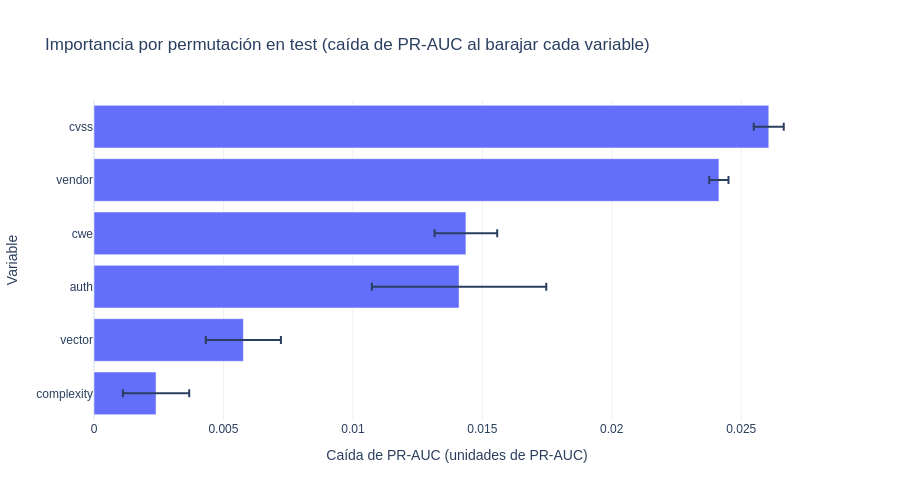

In [19]:
imp = permutation_importance(final, Xte, yte, scoring="average_precision", n_repeats=3, random_state=SEED, n_jobs=-1)
imp_df = pd.DataFrame({"variable": Xte.columns, "caída de PR-AUC": imp.importances_mean, "sd": imp.importances_std}).query("variable != 'epss'").sort_values("caída de PR-AUC")
fig = px.bar(imp_df, x="caída de PR-AUC", y="variable", orientation="h", error_x="sd", title="Importancia por permutación en test (caída de PR-AUC al barajar cada variable)")
fig.update_layout(xaxis_title="Caída de PR-AUC (unidades de PR-AUC)", yaxis_title="Variable"); show(fig)
RES["imp"] = imp_df.sort_values("caída de PR-AUC", ascending=False)

In [20]:
base_vals = {c: (train[c].median() if c == "cvss" else train[c].mode(dropna=True).iloc[0]) for c in RAW_COLUMNS}
def explain(i):
    row = test.loc[[i], RAW_COLUMNS + ["epss"]]
    p0 = final.predict_proba(row)[0, 1]; out = []
    for c in RAW_COLUMNS:
        alt = row.copy(); alt[c] = base_vals[c]
        out.append({"variable": c, "valor del CVE": row[c].iloc[0], "valor típico": base_vals[c], "cambio de probabilidad si fuera típico": final.predict_proba(alt)[0, 1] - p0})
    return p0, pd.DataFrame(out).sort_values("cambio de probabilidad si fuera típico")

t = test.assign(score=s_final, sel=m_mod)
casos = {"Acierto: explotado y en la lista": t[(t.y == 1) & t.sel].sort_values("score", ascending=False),
         "Fallo: explotado y fuera de la lista": t[(t.y == 1) & ~t.sel].sort_values("score", ascending=False),
         "Falsa alarma: en la lista y no explotado": t[(t.y == 0) & t.sel].sort_values("score", ascending=False)}
for titulo, c in casos.items():
    if len(c):
        i = c.index[0]; p0, ex = explain(i)
        display(Markdown(f"**{titulo}** — {t.loc[i, 'id']} (publicado {t.loc[i, 'published'].date()}), probabilidad del modelo {p0:.3f}"))
        display(ex.round(4))

**Acierto: explotado y en la lista** — CVE-2025-24085 (publicado 2025-01-27), probabilidad del modelo 0.975

,variable,valor del CVE,valor típico,cambio de probabilidad si fuera típico
4,cwe,NaN,CWE-79,-0.3822
0,cvss,10.0,6.7,-0.1779
5,vendor,apple,microsoft,-0.0388
1,vector,NETWORK,NETWORK,0.0000
3,auth,NONE,NONE,0.0000
2,complexity,LOW,LOW,0.0000


**Fallo: explotado y fuera de la lista** — CVE-2026-56155 (publicado 2026-07-14), probabilidad del modelo 0.903

,variable,valor del CVE,valor típico,cambio de probabilidad si fuera típico
0,cvss,7.8,6.7,-0.6207
1,vector,LOCAL,NETWORK,-0.3019
4,cwe,CWE-1220,CWE-79,-0.2756
3,auth,LOW,NONE,-0.0941
2,complexity,LOW,LOW,0.0000
5,vendor,microsoft,microsoft,0.0000


**Falsa alarma: en la lista y no explotado** — CVE-2025-43539 (publicado 2025-12-12), probabilidad del modelo 0.964

,variable,valor del CVE,valor típico,cambio de probabilidad si fuera típico
4,cwe,NaN,CWE-79,-0.4557
0,cvss,8.8,6.7,-0.1666
5,vendor,apple,microsoft,-0.0841
1,vector,NETWORK,NETWORK,0.0000
3,auth,NONE,NONE,0.0000
2,complexity,LOW,LOW,0.0000


> **Qué significa para el responsable.** Pesan más el CVSS (caída de PR-AUC de 0,026), el fabricante (0,024), el CWE (0,014) y la autenticación (0,014). El vector y la complejidad pesan poco por separado: H1 se apoya sobre todo en la autenticación. H3 se confirma: el fabricante es la segunda variable.
>
> En el acierto CVE-2025-24085 (0,975), un CVSS de 10 sube la probabilidad unos 0,18, y que falte el CWE la sube unos 0,38: hay que comprobar si esa ausencia es un artefacto. En el fallo CVE-2026-56155 (0,90), el CVE quedó fuera porque 30 CVEs de su semana puntuaron más. Las probabilidades están infladas (sección 7.1): sirven para ordenar, no como porcentaje.

## 10. Equidad, ética y riesgos

**Errores por grupo.** El modelo puede fallar más en grupos que importan. Se compara el recall de la lista por fabricante, CVSS, vector y año.

In [21]:
top_vendors = train[train.y == 1].vendor.value_counts().head(10).index
def group_report(name, groups):
    out = []
    for g, mask in groups.items():
        sub = (t.y.values == 1) & mask.values
        out.append({"agrupación": name, "grupo": g, "CVEs": int(mask.sum()), "explotados": int(sub.sum()),
                    "recall de la lista": (sub & t.sel.values).sum() / sub.sum() if sub.sum() else np.nan,
                    "% de CVEs en la lista": (t.sel.values & mask.values).sum() / mask.sum() * 100})
    return out
rep = (group_report("Vendor", {"10 vendors más explotados en train": t.vendor.isin(top_vendors), "resto de vendors": ~t.vendor.isin(top_vendors)})
     + group_report("CVSS", {"con CVSS": t.cvss.notna(), "sin CVSS": t.cvss.isna()})
     + group_report("Vector", {"con vector": t.vector.notna(), "sin vector": t.vector.isna()})
     + group_report("Año", {str(y): t.published.dt.year == y for y in sorted(t.published.dt.year.unique())}))
fair = pd.DataFrame(rep); display(fair.round(3))
RES["fair"] = fair

,agrupación,grupo,CVEs,explotados,recall de la lista,% de CVEs en la lista
0,Vendor,10 vendors más explotados en train,9219,110,0.445,11.400
1,Vendor,resto de vendors,78216,160,0.188,1.784
2,CVSS,con CVSS,82634,270,0.293,2.960
3,CVSS,sin CVSS,4801,0,NaN,0.000
4,Vector,con vector,82634,270,0.293,2.960
5,Vector,sin vector,4801,0,NaN,0.000
6,Año,2025,47722,159,0.327,3.317
7,Año,2026,39713,111,0.243,2.173


> **Qué significa para el responsable.** Fuera de los diez fabricantes más explotados, la cobertura cae del 44 % al 19 %. Ninguno de los 4.801 CVEs sin CVSS del test acabó en KEV a tiempo: el modelo no ha visto positivos en ese grupo y no debe priorizarlo solo.

**Datos personales.** Todo el conjunto es público y sin datos personales; el inventario del bloque 4 sí será sensible y se tratará fuera del repositorio.

**Qué pasa si falla, y para quién.**

| Riesgo | Quién lo sufre | Mitigación |
|---|---|---|
| Omite un CVE que se explota | Empresa y usuarios afectados | Todo CVE que entre en KEV se parchea con ventana de emergencia |
| Sesgo de KEV: infravalora software poco visto por el gobierno de EE. UU. | Equipos con productos poco representados | Mostrar el CVSS junto a la lista; revisar el recall por fabricante |
| Deriva del catálogo o de los atacantes | Todos | Monitorizar el recall@K mensual y reentrenar (bloque 4) |
| La lista llega tarde: el margen mediano del modelo es de 1 día | Equipo de parcheo | Ventana de emergencia para lo que ya se explota; EPSS histórico para ganar margen |
| Sobreconfianza en la lista | Responsable | Presentar el recall con su intervalo y las condiciones de la sección 11 |

## 11. Recomendación

La recomendación se calcula con el test y se traduce a los KPIs del brief: cobertura de KEV y carga de parcheo.

In [22]:
# Margen antes de KEV y semanas cubiertas (test). Solo se reporta: no se usa para elegir nada.
rows = []
for nombre, s in [("Modelo", s_final), ("Ordenar por CVSS", test["cvss"].values)]:
    mk = topk_mask(test, s, K)
    cubiertos = mk & (yte == 1)
    margen = test.loc[cubiertos, "days_to_kev"]
    semanas_ok = pd.Series(cubiertos).groupby(test["week"].values).any()
    rows.append({
        "lista": nombre,
        "explotados cubiertos": int(cubiertos.sum()),
        "% de los explotados en test": round(100 * cubiertos.sum() / yte.sum(), 1),
        "margen mediano antes de KEV (días)": round(float(margen.median()), 1) if len(margen) else np.nan,
        "% de semanas con al menos 1 cubierto": round(100 * semanas_ok.mean(), 1),
    })
RES["anticipacion"] = pd.DataFrame(rows)
display(RES["anticipacion"])

,lista,explotados cubiertos,% de los explotados en test,margen mediano antes de KEV (días),% de semanas con al menos 1 cubierto
0,Modelo,79,29.3,1.0,56.1
1,Ordenar por CVSS,53,19.6,8.0,47.6


> **Qué significa para el responsable.** El margen es el tiempo entre que el CVE aparece en la lista y que CISA lo declara explotado: 1 día para el modelo y 8 para CVSS. La mayoría de los aciertos del modelo entran en KEV casi el mismo día que se publican. Ayudan a ordenar, pero dan poco tiempo a una ventana semanal.

In [23]:
yrs = (test.published.max() - test.published.min()).days / 365.25
pos_year = yte.sum() / yrs
extra_year = (rec_mod - rec_cvss) * pos_year
tabla = pd.DataFrame([
    {"criterio": f"Lista de {K} CVEs por semana ordenada por el modelo", "cobertura de KEV": f"{rec_mod:.1%}", "precision": f"{RES['prec_mod']:.2%}", "carga": f"{K} CVEs/semana"},
    {"criterio": f"Lista de {K} CVEs por semana ordenada por CVSS", "cobertura de KEV": f"{rec_cvss:.1%}", "precision": f"{RES['prec_cvss']:.2%}", "carga": f"{K} CVEs/semana"},
    {"criterio": "Regla CVSS ≥ 7 (sin límite)", "cobertura de KEV": f"{r7t['recall']:.1%}", "precision": f"{r7t['precision']:.2%}", "carga": f"{r7t['carga semanal media']:.0f} CVEs/semana"},
])
display(tabla)
print(f"En el test hay unos {pos_year:.0f} CVEs/año que acaban en KEV en ≤ {HORIZON_DAYS} días. "
      f"A igual carga ({K}/semana), el modelo cubre unos {extra_year:.0f} CVEs más al año que ordenar por CVSS; "
      f"frente a la regla CVSS ≥ 7 reduce la carga de ~{r7t['carga semanal media']:.0f} a {K} tareas/semana "
      f"({1 - K / r7t['carga semanal media']:.0%} menos) con cobertura {rec_mod:.0%} frente a {r7t['recall']:.0%}.")
RES.update(extra_year=extra_year, pos_year=pos_year)

,criterio,cobertura de KEV,precision,carga
0,Lista de 30 CVEs por semana ordenada por el mo...,29.3%,3.23%,30 CVEs/semana
1,Lista de 30 CVEs por semana ordenada por CVSS,19.6%,2.17%,30 CVEs/semana
2,Regla CVSS ≥ 7 (sin límite),88.5%,0.61%,475 CVEs/semana


En el test hay unos 175 CVEs/año que acaban en KEV en ≤ 90 días. A igual carga (30/semana), el modelo cubre unos 17 CVEs más al año que ordenar por CVSS; frente a la regla CVSS ≥ 7 reduce la carga de ~475 a 30 tareas/semana (94% menos) con cobertura 29% frente a 89%.


### Recomendación

1. **Qué hacer.** Usar el orden del modelo en lugar del de CVSS, que cuesta menos en validación con los dos K comprobados (5 y 30). Fijar K con el responsable según el coste real de omitir (sección 7.1); con 20 a 1, una lista de 5 es más barata.
2. **Mejora esperada.** Con 30 CVEs por semana, cubre el 29 % frente al 20 % de CVSS (unos 17 CVEs más al año). Frente a CVSS ≥ 7 (89 % con unas 475 tareas por semana), la carga baja un 94 % a cambio de unos 60 puntos de cobertura.
3. **Límite de anticipación.** El margen mediano es de 1 día: la mejora real está en ordenar lo que ya se explota, no en avisar con antelación.
4. **Cuándo no fiarse.** Fuera de los diez fabricantes más explotados (44 % frente a 19 % de cobertura), con CVEs sin CVSS, o si la cobertura real mensual cae por debajo del 20 %.
5. **Pendiente.** EPSS histórico de los días posteriores a la publicación (cierra H2 y da margen real); validar el ratio de coste; cruzar con el inventario real.
6. **Bloque 4.** Despliegue, monitorización e impacto para la defensa.

## 12. Guardado del modelo

El modelo final es **un único pipeline** (`features.py` + codificación + gradient boosting), de columnas crudas a probabilidad, guardado con `joblib`. Se recarga y se usa en una predicción para comprobar que funciona. Para cargarlo en otro sitio hacen falta `model.joblib` y `features.py` juntos, y las mismas versiones de librerías (se imprimen abajo).

> **Qué significa para el responsable.** El modelo queda en un solo fichero que el equipo puede cargar sin rehacer el análisis, siempre que se usen las mismas versiones de librerías. El 0,28 que imprime la última celda es un índice de orden, no una probabilidad (sección 7.1).

In [24]:
joblib.dump(final, "model.joblib", compress=3)
size_mb = Path("model.joblib").stat().st_size / 1e6
print(f"model.joblib: {size_mb:.1f} MB " + ("(se puede subir al repositorio)" if size_mb < 50 else "(> 50 MB: no subir; reconstruir ejecutando este notebook)"))

reloaded = joblib.load("model.joblib")
ejemplo = test[RAW_COLUMNS].iloc[[0]]
display(ejemplo)
print("Probabilidad de entrar en KEV a tiempo:", float(reloaded.predict_proba(ejemplo.assign(epss=np.nan))[0, 1]))
assert np.allclose(reloaded.predict_proba(Xte.iloc[:200])[:, 1], final.predict_proba(Xte.iloc[:200])[:, 1])

print("Python", sys.version.split()[0], "· scikit-learn", sklearn.__version__, "· pandas", pd.__version__,
      "· numpy", np.__version__, "· joblib", joblib.__version__)

model.joblib: 0.2 MB (se puede subir al repositorio)


,cvss,vector,complexity,auth,cwe,vendor
107877,6.1,NETWORK,LOW,NONE,NaN,NaN


Probabilidad de entrar en KEV a tiempo: 0.2833625194844994
Python 3.14.9 · scikit-learn 1.9.1 · pandas 3.1.1 · numpy 2.5.4 · joblib 1.6.0


In [25]:
mejor = RES["rec_mod"] > RES["rec_cvss"] and RES["ci"][0] > 0
borrador = f"""
- **Pregunta.** ¿Pueden los datos públicos de cada CVE anticipar cuáles entrarán en el catálogo KEV de CISA en ≤ {HORIZON_DAYS} días, para decidir qué parchear cada semana?
- **Modelo.** Gradient boosting en un pipeline único, entrenado con CVEs de 2021-2024 y probado una sola vez con CVEs de 2025 en adelante, sin usar EPSS de hoy (tendría fuga).
- **Mejora.** Con una ventana de {K} CVEs/semana cubre el {RES['rec_mod']:.0%} de los CVEs que acaban en KEV, frente al {RES['rec_cvss']:.0%} de ordenar por CVSS (diferencia {RES['rec_mod']-RES['rec_cvss']:+.0%}; IC 95 %: {RES['ci'][0]:+.0%} a {RES['ci'][1]:+.0%}). La regla CVSS ≥ 7 cubre el {RES['rule7']['recall']:.0%}, pero con ~{RES['rule7']['carga semanal media']:.0f} tareas/semana.
- **Recomendación.** {"Usar la lista del modelo en lugar del orden por CVSS, manteniendo la ventana de emergencia para todo CVE que entre en KEV." if mejor else "La mejora sobre CVSS no es concluyente en este test: usar el modelo como apoyo y no como sustituto hasta tener más datos (EPSS histórico)."}
- **Límite principal.** KEV solo recoge lo que CISA ha visto explotar, y la mejora debe confirmarse con el EPSS de los días posteriores a la publicación y con el inventario real.
"""
display(Markdown(borrador))


- **Pregunta.** ¿Pueden los datos públicos de cada CVE anticipar cuáles entrarán en el catálogo KEV de CISA en ≤ 90 días, para decidir qué parchear cada semana?
- **Modelo.** Gradient boosting en un pipeline único, entrenado con CVEs de 2021-2024 y probado una sola vez con CVEs de 2025 en adelante, sin usar EPSS de hoy (tendría fuga).
- **Mejora.** Con una ventana de 30 CVEs/semana cubre el 29% de los CVEs que acaban en KEV, frente al 20% de ordenar por CVSS (diferencia +10%; IC 95 %: +3% a +16%). La regla CVSS ≥ 7 cubre el 89%, pero con ~475 tareas/semana.
- **Recomendación.** Usar la lista del modelo en lugar del orden por CVSS, manteniendo la ventana de emergencia para todo CVE que entre en KEV.
- **Límite principal.** KEV solo recoge lo que CISA ha visto explotar, y la mejora debe confirmarse con el EPSS de los días posteriores a la publicación y con el inventario real.


## 13. Referencias

Cybersecurity and Infrastructure Security Agency. (2026). *Known Exploited Vulnerabilities Catalog* [Conjunto de datos]. https://www.cisa.gov/known-exploited-vulnerabilities-catalog (descargado el 18 de octubre de 2026; licencia CC0 1.0)

Forum of Incident Response and Security Teams. (2026). *Exploit Prediction Scoring System (EPSS)* [Conjunto de datos]. https://www.first.org/epss/ (descargado el 18 de octubre de 2026)

Jacobs, J., Romanosky, S., Edwards, B., Adjerid, I., & Roytman, M. (2021). Exploit Prediction Scoring System (EPSS). *Digital Threats: Research and Practice, 2*(3), 1-17. https://doi.org/10.1145/3436242

MITRE Corporation. (2026). *CVE List V5* [Conjunto de datos]. CVE Program. https://github.com/CVEProject/cvelistV5 (descargado el 18 de octubre de 2026)

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.

Plotly Technologies Inc. (2015). *Collaborative data science* [Software]. https://plot.ly

The pandas development team. (2020). *pandas-dev/pandas: Pandas* [Software]. Zenodo. https://doi.org/10.5281/zenodo.3509134

> Añade cualquier otra fuente que uses (artículos, documentación de la unidad) en formato APA.